In [338]:
import numpy as np
import pandas as pd
import scipy

import matplotlib as mpl
import matplotlib.pyplot as plt

import odrpack as odr
import uncertainties

from uncertainties import nominal_value, std_dev
from uncertainties import ufloat
from uncertainties import unumpy as unp

In [339]:
df = pd.read_excel("p1ssp.xlsx", sheet_name="Sheet1", decimal = ",")


rawLenArray = np.array(df.iloc[:, 1:5]) * 10**-3

lenMeans = np.mean(rawLenArray, axis = 1)
lenStd = np.std(rawLenArray, axis = 1)

lengths = unp.uarray(lenMeans, lenStd)

rMedias = lengths / 2


V = unp.uarray(df["V (kV)"], len(df["V (kV)"]) * [0.01]) * 1000

In [340]:
X = 1 / unp.sqrt(V)
Y = rMedias

In [341]:
#=============================== Blocón de ODR_FIT ===============================

def func(x, beta):
    return beta[0] * x + beta[1]


beta0 = [0.03, 0]

fittingX = unp.nominal_values(X)
fittingY = unp.nominal_values(Y)
fittingXUncertainty = unp.std_devs(X)
fittingYUncertainty = unp.std_devs(Y)

sol = odr.odr_fit(func, fittingX, fittingY, beta0, weight_x=1 / (fittingXUncertainty ** 2),
                  weight_y=1 / (fittingYUncertainty ** 2))

pendiente = ufloat(sol.beta[0], sol.sd_beta[0])  #np.sqrt(sol.cov_beta[0,0]))
ordenada = ufloat(sol.beta[1], sol.sd_beta[1])  #np.sqrt(sol.cov_beta[1,1]))

print("pendiente = {:.4f}".format(pendiente))
print("ordenada = {:.4f}".format(ordenada))

print(f"χ² reducido = {sol.sum_square / (len(unp.nominal_values(X)) - len(sol.beta))}")
#print(f"pearson = {scipy.stats.pearsonr(fittingX, fittingY).statistic}")
print(f"R² = {scipy.stats.pearsonr(fittingX, fittingY).statistic ** 2}")

#=================================================================================

pendiente = 0.9293+/-0.0464
ordenada = -0.0012+/-0.0008
χ² reducido = 0.030251334316100113
R² = 0.981559928129823


In [342]:
HPLANCK = 6.62607015e-34
EMASS = 9.1093837139e-31
ECHARGE = 1.602176634e-19

d1 = 213e-12
d2 = 123e-12

distancial = 13.5e-2

h = pendiente * unp.sqrt(2*EMASS*ECHARGE)*d1/distancial

print("h = {:.4e}".format(h))
print(f"error relativo = {np.abs((HPLANCK-nominal_value(h))/HPLANCK) * 100}")

h = (7.9219+/-0.3959)e-34
error relativo = 19.55719894782161


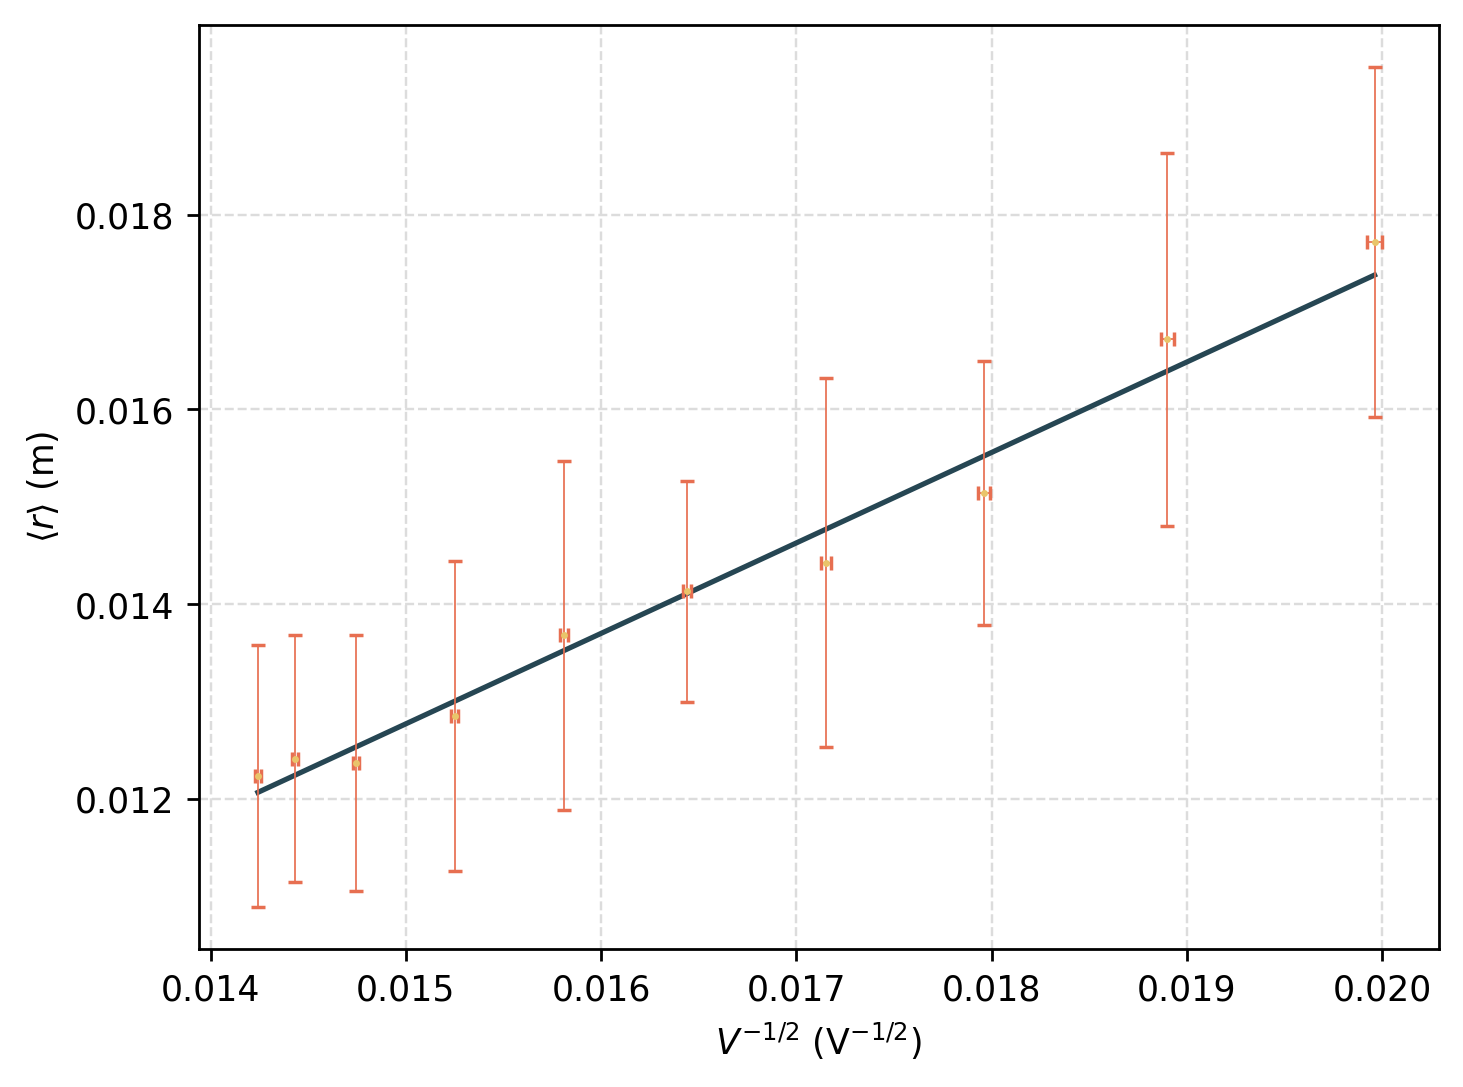

In [343]:
fig, ax = plt.subplots(dpi = 250)

ax.errorbar(x = unp.nominal_values(X), y = unp.nominal_values(Y), xerr = unp.std_devs(X), yerr = unp.std_devs(Y), color = "#e9c46a", ls = "", marker = ".", markersize = 2, ecolor = "#e76f51", capsize=2, zorder = 10, elinewidth=.5)

ax.plot(unp.nominal_values(X), func(unp.nominal_values(X), sol.beta), color = "#264653")

ax.set(xlabel = r"$V^{-1/2}$ (V$^{-1/2}$)", ylabel = r"$\langle r \rangle$ (m)")

ax.grid(zorder=0,color='gainsboro', linestyle='--', linewidth=0.7)

plt.savefig("ajusteh1.png", bbox_inches = "tight")

plt.show()

In [344]:
df = pd.read_excel("p1ssp.xlsx", sheet_name="Sheet3", decimal = ",")


rawLenArray = np.array(df.iloc[:, 1:5])* 10**-3

lenMeans = np.mean(rawLenArray, axis = 1)
lenStd = np.std(rawLenArray, axis = 1)

lengths = unp.uarray(lenMeans, lenStd)

rMedias = lengths / 2


V = unp.uarray(df["V (kV)"], len(df["V (kV)"]) * [0.01]) * 1000

In [345]:
X = 1 / unp.sqrt(V)
Y = rMedias

In [346]:
#=============================== Blocón de ODR_FIT ===============================

def func(x, beta):
    return beta[0] * x + beta[1]


beta0 = [0.03, 0]

fittingX = unp.nominal_values(X)
fittingY = unp.nominal_values(Y)
fittingXUncertainty = unp.std_devs(X)
fittingYUncertainty = unp.std_devs(Y)

sol = odr.odr_fit(func, fittingX, fittingY, beta0, weight_x=1 / (fittingXUncertainty ** 2),
                  weight_y=1 / (fittingYUncertainty ** 2))

pendiente = ufloat(sol.beta[0], sol.sd_beta[0])  #np.sqrt(sol.cov_beta[0,0]))
ordenada = ufloat(sol.beta[1], sol.sd_beta[1])  #np.sqrt(sol.cov_beta[1,1]))

print("pendiente = {:.4f}".format(pendiente))
print("ordenada = {:.4f}".format(ordenada))

print(f"χ² reducido = {sol.sum_square / (len(unp.nominal_values(X)) - len(sol.beta))}")
#print(f"pearson = {scipy.stats.pearsonr(fittingX, fittingY).statistic}")
print(f"R² = {scipy.stats.pearsonr(fittingX, fittingY).statistic ** 2}")

#=================================================================================

pendiente = 1.2478+/-0.0425
ordenada = 0.0037+/-0.0007
χ² reducido = 0.019295612829149725
R² = 0.9911541778603207


In [347]:
HPLANCK = 6.62607015e-34
EMASS = 9.1093837139e-31
ECHARGE = 1.602176634e-19

d1 = 213e-12
d2 = 123e-12

distancial = 13.5e-2

h = pendiente * unp.sqrt(2*EMASS*ECHARGE)*d2/distancial

print("h = {:.4e}".format(h))
print(f"error relativo = {np.abs((HPLANCK-nominal_value(h))/HPLANCK) * 100}")

h = (6.1421+/-0.2092)e-34
error relativo = 7.303425046609161


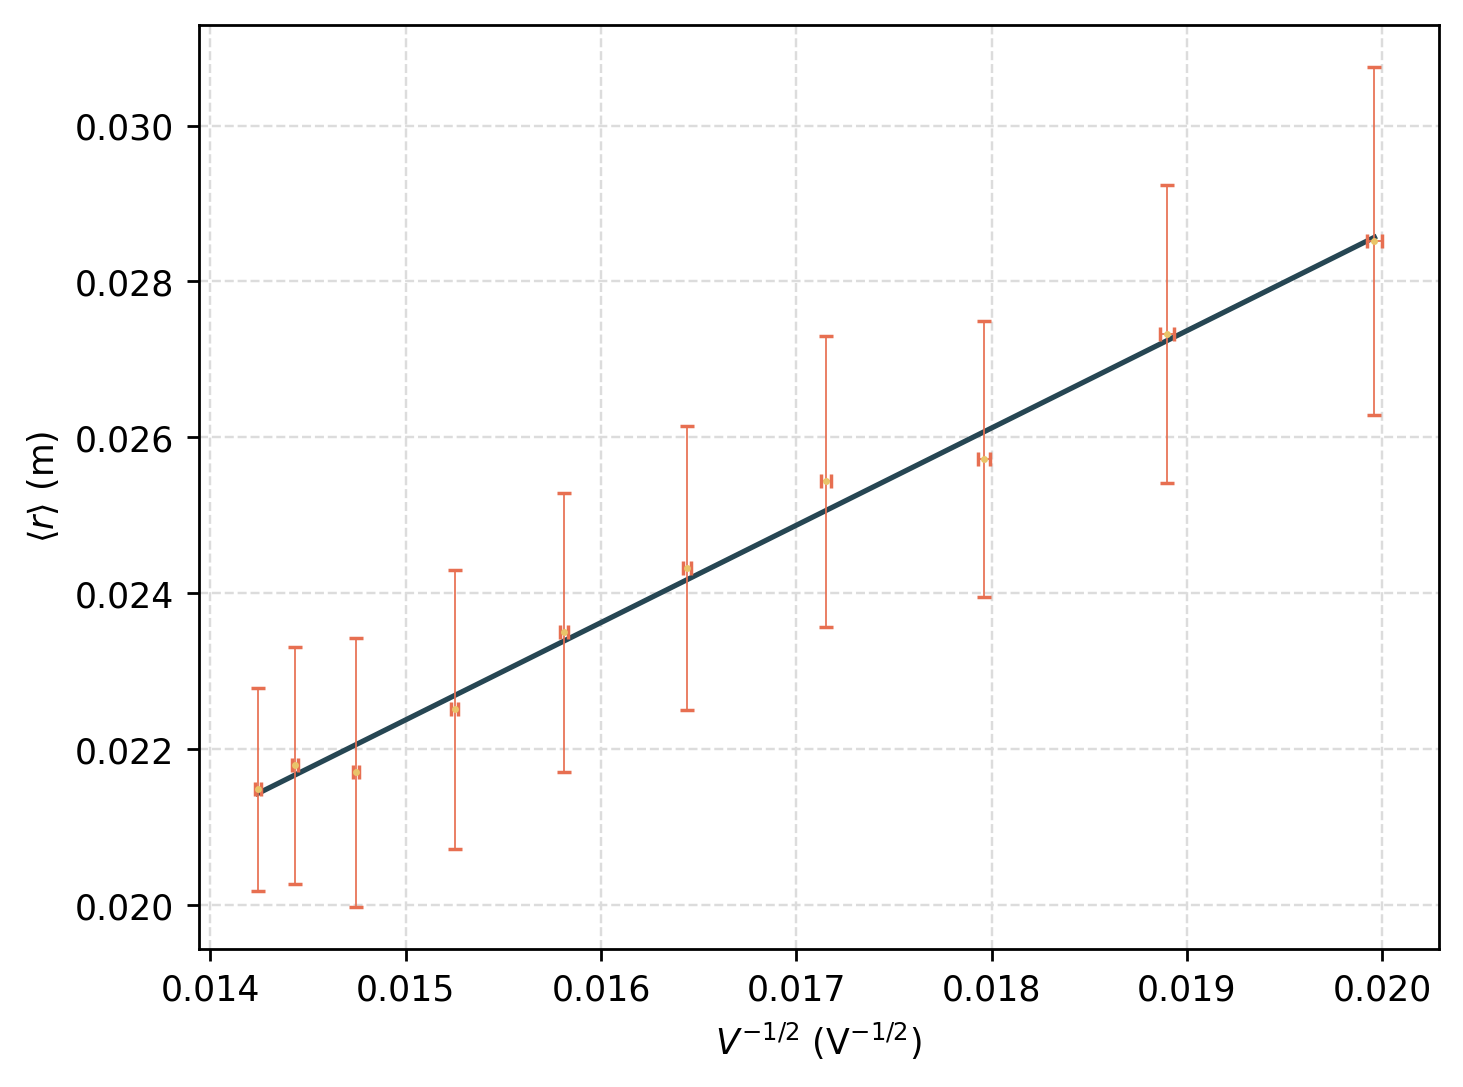

In [348]:
fig, ax = plt.subplots(dpi = 250)

ax.errorbar(x = unp.nominal_values(X), y = unp.nominal_values(Y), xerr = unp.std_devs(X), yerr = unp.std_devs(Y), color = "#e9c46a", ls = "", marker = ".", markersize = 2, ecolor = "#e76f51", capsize=2, zorder = 10, elinewidth=.5)

ax.plot(unp.nominal_values(X), func(unp.nominal_values(X), sol.beta), color = "#264653")

ax.set(xlabel = r"$V^{-1/2}$ (V$^{-1/2}$)", ylabel = r"$\langle r \rangle$ (m)")

ax.grid(zorder=0,color='gainsboro', linestyle='--', linewidth=0.7)

plt.savefig("ajusteh2.png", bbox_inches = "tight")

plt.show()